# 18 - Predire en production : un predicteur ONNX sans PyTorch, un service HTTP, des fichiers de reference C#

En production, il n'y a ni PyTorch ni la toolbox : un programme (C#, C++, Python) lit
`model.onnx` et `model_card.json`, prepare l'image comme la carte le dit, execute le reseau avec
ONNX Runtime et transforme les sorties en decision. Ce notebook ecrit ce programme A LA MAIN en
Python (numpy, OpenCV, onnxruntime), pour les quatre taches :
1. lire la carte et l'image (couleur de lecture, 8 / 16 bits, chemins Windows) ;
2. appliquer le pretraitement de la carte, puis la mise en forme de l'entree (stretch, letterbox,
   couleur, mise a l'echelle, normalisation, NCHW) ;
3. post-traiter : softmax (classification), seuil (anomalie), masque et surface (segmentation),
   decodage + NMS + retour aux coordonnees d'origine (detection YOLO) ;
4. l'exposer en service HTTP (FastAPI), teste sans reseau ;
5. ecrire les fichiers de reference (golden) que le programme C# doit reproduire a l'identique.

Ce code est la specification executable du programme C# (`csharp/`) : s'il rend les memes
reponses que la toolbox (section 7), la carte est complete et le portage peut s'ecrire en la lisant.

Modeles : ceux du notebook 17 (`outputs/notebooks/17_export_onnx/`) et, s'ils existent, ceux des
recettes (`outputs/<tache>/<experience>/`). Le segmenteur du notebook 17 a un decodeur non entraine :
son masque n'a pas de sens, seule la chaine est verifiee. Prerequis : extra `serve` (FastAPI, httpx).
Duree sur un CPU 2 coeurs : moins d'une minute. Lancer depuis la racine du depot.

**Dans le fil** : ce notebook approfondit l'etape 13 (Predire).
Le fil des 13 etapes, le meme que dans le cours : `ETAPES.md`, a la racine de la toolbox.

## 0. Reglages

Un modele = un dossier exporte + un dossier d'images representatives. Les dossiers absents sont
ignores : lancer d'abord le notebook 17 (et, pour les quatre taches, les recettes).

In [1]:
import json  # json : lire la carte du modele, ecrire les reponses et les fichiers de reference
import shutil  # shutil : copier des fichiers (les images de reference)
import time  # time : chronometre, pour mesurer la duree d'une prediction
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux
from typing import Annotated  # Annotated : ajoute une information a un type (ici : "ce parametre est un fichier envoye")

import cv2  # OpenCV : lecture et traitement d'images
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import onnxruntime as ort  # ONNX Runtime : execute un modele .onnx (ONNX = format standard de reseau, sans PyTorch)
import pandas as pd  # pandas : tableaux de donnees (DataFrame)

# FastAPI : creer un service web (HTTP) ; File / UploadFile : fichier envoye au service ; HTTPException : reponse d'erreur
from fastapi import FastAPI, File, HTTPException, UploadFile
from fastapi.testclient import TestClient  # TestClient : appelle le service directement, sans reseau
from IPython.display import display  # display : affiche joliment un tableau dans le notebook

from vtb import viz  # module d'affichage de la toolbox (grilles, superpositions, boites)

QUICK = True  # sans effet ici : tout tourne en moins d'une minute
N_GOLDEN = 5  # images de reference par modele pour le programme C#
CANDIDATES = {  # modeles possibles ; nom : (dossier du modele exporte, dossier d'images, extensions)
    # classifieur exporte au notebook 17, images de la classe crazing
    "classification (notebook 17)": ("outputs/notebooks/17_export_onnx/classifier", "data/raw/neu_cls_flat/crazing", (".bmp",)),
    # segmenteur exporte au notebook 17, images de fissures
    "segmentation (notebook 17)": ("outputs/notebooks/17_export_onnx/segmenter", "data/raw/magnetic_tile/MT_Crack/Imgs", (".jpg",)),
    # classifieur de la recette classification, images de rayures
    "classification (recette)": ("outputs/classification/resnet18_head", "data/raw/neu_cls_flat/scratches", (".bmp",)),
    # modele d'anomalie (PatchCore allege) de la recette anomalie, bouteilles cassees
    "anomalie (recette)": ("outputs/anomaly/patchcore_lite_bottle", "data/raw/mvtec_bottle/test/broken_large", (".png",)),
    # U-Net de la recette segmentation, tuiles cassees
    "segmentation (recette)": ("outputs/segmentation/unet_resnet18_tile_cpu", "data/raw/magnetic_tile/MT_Break/Imgs", (".jpg",)),
    # detecteur YOLO de la recette detection, images de validation NEU-DET
    "detection (recette)": ("outputs/detection/quick_yolo", "data/raw/neu_det/Validation_Images", (".jpg",)),
}
OUT = Path("outputs/notebooks/18_prediction_production")  # dossier de sortie du notebook
OUT.mkdir(parents=True, exist_ok=True)  # le creer (et ses parents) ; pas d'erreur s'il existe deja
viz.setup_notebook(dpi=80, fmt="jpeg")  # figures en 80 points par pouce et en JPEG : notebook plus leger

MODELS = {  # modeles presents sur le disque : nom -> (dossier du modele, liste triee de ses images)
    name: (Path(model), sorted(p for p in Path(images).glob("*") if p.suffix.lower() in ext))  # images filtrees par extension
    for name, (model, images, ext) in CANDIDATES.items()  # pour chaque modele candidat
    if (Path(model) / "model_card.json").exists()  # seulement ceux deja exportes (leur carte existe)
}
missing = sorted(set(CANDIDATES) - set(MODELS))  # noms des modeles absents (difference de deux ensembles)
print("modeles trouves :", ", ".join(MODELS) or "aucun (lancer le notebook 17)")  # `or` : texte de secours si rien trouve
if missing:  # s'il manque des modeles
    print("absents (ignores) :", ", ".join(missing))  # on les signale

modeles trouves : classification (notebook 17), segmentation (notebook 17), classification (recette), anomalie (recette), segmentation (recette), detection (recette)


## 1. La carte et l'image

La carte est un simple JSON. Le champ `input.read_color` dit comment LIRE le fichier, avant tout
pretraitement : un modele de detection entraine sur des images grises lit en gris puis copie sur
3 canaux. OpenCV lit en BGR : on convertit en RGB une fois, a la lecture. `imdecode` sur les
octets du fichier evite l'echec silencieux d'`imread` sur les chemins Windows avec accents.

In [2]:
def read_card(model_dir: Path) -> dict:  # lit la carte du modele (model_card.json) et la renvoie en dict
    return json.loads((Path(model_dir) / "model_card.json").read_text(encoding="utf-8"))  # texte du fichier -> dict Python


def read_image(path: str | Path, color: str) -> np.ndarray:  # lit une image comme le dit la carte : "gray" ou "rgb"
    image = cv2.imdecode(np.fromfile(str(path), np.uint8), cv2.IMREAD_UNCHANGED)  # 8 ou 16 bits, tel que stocke
    if image is None:  # None = le fichier n'est pas une image lisible
        raise ValueError(f"image illisible : {path}")  # on arrete avec un message clair
    if image.ndim == 3:  # image couleur (3 dimensions : hauteur, largeur, canaux)
        image = image[..., :3]  # canal alpha ignore
    if color == "gray":  # lecture en gris demandee
        return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image  # couleur -> gris ; grise : inchangee
    return np.stack([image] * 3, axis=-1) if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # gris -> 3 canaux ; BGR -> RGB


def max_value(image: np.ndarray) -> float:  # valeur maximale possible selon le type : sert a ramener les pixels dans [0, 1]
    return 255.0 if image.dtype == np.uint8 else 65535.0 if image.dtype == np.uint16 else 1.0  # 8 bits, 16 bits, deja flottante


for name, (model_dir, _) in MODELS.items():  # pour chaque modele trouve (_ : la liste d'images, inutile ici)
    card = read_card(model_dir)  # sa carte
    spec = card["input"]  # la partie "comment preparer l'entree"
    print(  # une ligne de resume : tache, modele, lecture, pretraitement, taille, couleur, normalisation, sorties
        f"{name:30s} {card['task']:15s} {card['model_name']:22s} lecture {spec.get('read_color') or '-':4s} -> "
        f"{[s['name'] for s in card['preprocess']]} -> {spec['resize']} {spec['height']}x{spec['width']} {spec['color']} "
        f"normalisation {'oui' if spec['mean'] else 'non'} | sorties {[o['name'] for o in card['outputs']]}"
    )

classification (notebook 17)   classification  resnet18               lecture rgb  -> ['resize'] -> stretch 128x128 RGB normalisation oui | sorties ['logits']
segmentation (notebook 17)     segmentation    unet_resnet18          lecture gray -> ['resize'] -> stretch 128x128 GRAY normalisation non | sorties ['probabilities']
classification (recette)       classification  resnet18               lecture -    -> ['resize'] -> stretch 128x128 RGB normalisation oui | sorties ['logits']
anomalie (recette)             anomaly         patchcore_lite         lecture rgb  -> ['resize'] -> stretch 256x256 RGB normalisation non | sorties ['anomaly_map', 'score']
segmentation (recette)         segmentation    unet_resnet18          lecture gray -> ['resize'] -> stretch 128x128 GRAY normalisation non | sorties ['probabilities']
detection (recette)            detection       ultralytics:yolo11n    lecture gray -> [] -> letterbox 320x320 RGB normalisation non | sorties ['output0']


## 2. Le pretraitement de la carte, puis la mise en forme de l'entree

`preprocess` liste des operations OpenCV nommees, dans l'ordre : on les porte une par une, a
l'identique (meme interpolation, meme arrondi). Une operation non portee doit lever une erreur
claire, jamais etre ignoree en silence. Puis, dans cet ordre :
- 3 canaux si le reseau en attend 3 et que l'image est grise ;
- `letterbox` (YOLO) : reduction sans deformer, centree, bordure grise 114 ; on garde le ratio et
  le decalage pour ramener les boites dans l'image ; `letterbox_top_left` (YOLOX) : collee en haut
  a gauche ;
- BGR si demande (YOLOX), division par 255 (65535 en 16 bits) sauf `scale: none` ;
- `stretch` : redimensionnement sans garder les proportions (RF-DETR) s'il reste a faire ;
- HWC -> CHW, normalisation (mean / std) si la carte en donne, ajout de la dimension du lot.

In [3]:
# noms d'interpolation ecrits dans la carte -> constantes OpenCV correspondantes
INTERPOLATIONS = {"nearest": cv2.INTER_NEAREST, "linear": cv2.INTER_LINEAR, "area": cv2.INTER_AREA, "cubic": cv2.INTER_CUBIC}


# operation "resize" de la carte : redimensionne l'image ; renvoie l'image redimensionnee
def op_resize(image: np.ndarray, size: int | list[int] = 256, interpolation: str = "auto") -> np.ndarray:
    height, width = (size, size) if isinstance(size, int) else size  # size : un entier (carre) ou [hauteur, largeur]
    if interpolation == "auto":  # INTER_AREA pour reduire (pas de moirage), INTER_LINEAR pour agrandir
        flag = cv2.INTER_AREA if height * width < image.shape[0] * image.shape[1] else cv2.INTER_LINEAR  # moins de pixels -> AREA
    else:  # interpolation nommee dans la carte
        flag = INTERPOLATIONS[interpolation]  # constante OpenCV correspondante
    return cv2.resize(image, (width, height), interpolation=flag)  # attention : OpenCV attend (largeur, hauteur)


def op_gaussian_blur(image: np.ndarray, sigma: float = 1.0) -> np.ndarray:  # operation "gaussian_blur" : flou gaussien
    return cv2.GaussianBlur(image, (0, 0), sigmaX=float(sigma), borderType=cv2.BORDER_REFLECT)  # (0, 0) : noyau deduit de sigma


def op_median_blur(image: np.ndarray, ksize: int = 3) -> np.ndarray:  # operation "median_blur" : filtre median
    return cv2.medianBlur(image, int(ksize) | 1)  # | 1 force une taille impaire (exigee par OpenCV)


OPERATIONS = {"resize": op_resize, "gaussian_blur": op_gaussian_blur, "median_blur": op_median_blur}  # nom -> fonction portee


def apply_preprocess(image: np.ndarray, steps: list[dict]) -> np.ndarray:  # applique les operations de la carte, dans l'ordre
    for step in steps:  # pour chaque operation de la liste
        params = {k: v for k, v in step.items() if k != "name"}  # ses parametres : tout sauf la cle "name"
        if step["name"] not in OPERATIONS:  # operation inconnue (pas encore portee)
            # erreur claire plutot qu'un oubli silencieux (l'image serait mal preparee sans que personne le voie)
            raise NotImplementedError(f"operation '{step['name']}' non portee : la reprendre de src/vtb/preprocess/ops/")
        image = OPERATIONS[step["name"]](image, **params)  # appelle la fonction ; **params passe le dict en arguments nommes
    return image  # l'image apres toutes les operations


# letterbox : reduire l'image sans la deformer pour qu'elle tienne dans size x size, puis la centrer sur une bordure
def letterbox_params(height: int, width: int, size: int) -> tuple[float, int, int, int, int]:  # renvoie ratio, taille, decalages
    ratio = min(size / height, size / width)  # facteur de reduction qui fait tenir l'image entiere
    new_w, new_h = round(width * ratio), round(height * ratio)  # taille reduite, proportions gardees
    return ratio, new_w, new_h, (size - new_w) // 2, (size - new_h) // 2  # decalages x et y pour centrer l'image


# image lue -> tenseur d'entree du reseau ; renvoie (tenseur, infos pour revenir aux coordonnees d'origine)
def prepare(card: dict, image: np.ndarray) -> tuple[np.ndarray, dict]:
    """Image lue -> tenseur (1, C, H, W) float32 + ce qu'il faut pour revenir aux coordonnees d'origine."""
    spec = card["input"]  # description de l'entree du reseau
    processed = apply_preprocess(image, card["preprocess"])  # operations OpenCV de la carte
    # tailles d'origine et apres pretraitement, ratio et bordure du letterbox (valeurs neutres par defaut)
    meta = {"original_hw": image.shape[:2], "processed_hw": processed.shape[:2], "ratio": 1.0, "pad": (0, 0)}
    x = processed  # x : l'image en cours de mise en forme
    if spec["channels"] == 3 and x.ndim == 2:  # le reseau veut 3 canaux mais l'image est grise
        x = np.stack([x] * 3, axis=-1)  # copie le gris sur 3 canaux
    pad_value = spec.get("letterbox_pad_value") or 114  # gris de la bordure ; 114 par defaut (convention YOLO)
    if spec["resize"] == "letterbox":  # letterbox centre (YOLO) : reduire sans deformer, bordure grise autour
        ratio, new_w, new_h, pad_x, pad_y = letterbox_params(x.shape[0], x.shape[1], spec["height"])  # ratio et decalages
        # toile pleine de la couleur de bordure, a la taille du reseau ; *x.shape[2:] garde le nombre de canaux
        canvas = np.full((spec["height"], spec["width"], *x.shape[2:]), pad_value, dtype=x.dtype)
        # colle l'image reduite au centre de la toile (lignes pad_y a pad_y + new_h, colonnes pad_x a pad_x + new_w)
        canvas[pad_y : pad_y + new_h, pad_x : pad_x + new_w] = cv2.resize(x, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
        x = canvas  # la toile devient l'image
        meta.update(ratio=ratio, pad=(pad_x, pad_y))  # garde ratio et bordure pour ramener les boites dans l'image
    elif spec["resize"] == "letterbox_top_left":  # variante YOLOX : image reduite collee en haut a gauche
        ratio = min(spec["height"] / x.shape[0], spec["width"] / x.shape[1])  # facteur pour tenir dans la taille du reseau
        # image reduite (int() tronque les tailles, comme YOLOX)
        resized = cv2.resize(x, (int(x.shape[1] * ratio), int(x.shape[0] * ratio)), interpolation=cv2.INTER_LINEAR)
        canvas = np.full((spec["height"], spec["width"], 3), pad_value, dtype=x.dtype)  # toile de la couleur de bordure, 3 canaux
        canvas[: resized.shape[0], : resized.shape[1]] = resized  # colle l'image en haut a gauche
        x = canvas  # la toile devient l'image
        meta.update(ratio=ratio)  # pas de decalage ici : seul le ratio compte
    if spec["color"] == "BGR":  # le reseau attend l'ordre BGR (cas de YOLOX)
        x = x[..., ::-1]  # inverse l'ordre des canaux : RGB -> BGR
    values = x.astype(np.float32)  # en flottants 32 bits
    if not spec["scale"].startswith("none"):  # sauf si la carte dit "pas de mise a l'echelle"
        values /= max_value(x)  # ramene dans [0, 1] : / 255 ou / 65535 selon le type d'origine
    if spec["resize"] == "stretch" and values.shape[:2] != (spec["height"], spec["width"]):  # stretch : taille pas encore atteinte
        values = cv2.resize(values, (spec["width"], spec["height"]), interpolation=cv2.INTER_LINEAR)  # sans garder les proportions
    values = values[None] if values.ndim == 2 else values.transpose(2, 0, 1)  # gris -> (1, H, W) ; HWC -> CHW (canaux d'abord)
    if spec["mean"]:  # la carte donne une normalisation (liste non vide)
        # normalisation : (valeur - moyenne) / ecart-type, canal par canal ; [:, None, None] applique a chaque pixel
        values = (values - np.array(spec["mean"], np.float32)[:, None, None]) / np.array(spec["std"], np.float32)[:, None, None]
    # values[None] ajoute la dimension du lot -> (1, C, H, W) ; memoire contigue, comme l'attend ONNX Runtime
    return np.ascontiguousarray(values[None], dtype=np.float32), meta


name, (model_dir, paths) = next(iter(MODELS.items()))  # le premier modele trouve
# prepare sa premiere image, lue avec la couleur de la carte (rgb par defaut)
tensor, meta = prepare(read_card(model_dir), read_image(paths[0], read_card(model_dir)["input"].get("read_color") or "rgb"))
print(f"{name} : tenseur {tensor.shape} {tensor.dtype}, min {tensor.min():.3f}, max {tensor.max():.3f} | {meta}")  # controle

classification (notebook 17) : tenseur (1, 3, 128, 128) float32, min -0.936, max 2.605 | {'original_hw': (200, 200), 'processed_hw': (128, 128), 'ratio': 1.0, 'pad': (0, 0)}


## 3. Le post-traitement, tache par tache

- classification : softmax des logits (en float64, apres soustraction du max : pas de debordement) ;
- anomalie : le score image compare au seuil de la carte (quantile 0,99 des saines de
  validation) ; la carte d'anomalie donne en plus la surface au-dessus du seuil pixel ;
- segmentation : 2 classes -> pixel defaut si probabilite > `defect_probability`, sinon argmax ;
  l'image est signalee si la surface de defaut atteint `min_defect_area` ;
- detection YOLO (ultralytics) : sortie (1, 4 + C, A) -> transposer -> score max par ancre ->
  filtre `conf` -> centre / taille -> coins -> NMS PAR CLASSE -> retirer la bordure du letterbox
  et diviser par le ratio -> repere de l'image d'origine. La NMS tient en 15 lignes de numpy.

In [4]:
def softmax(logits: np.ndarray) -> np.ndarray:  # transforme des logits (scores bruts) en probabilites qui somment a 1
    z = np.exp(logits.astype(np.float64) - logits.max())  # exponentielle apres soustraction du max : pas de debordement
    return z / z.sum()  # divise par la somme : des probabilites


def nms(boxes: np.ndarray, scores: np.ndarray, iou: float) -> np.ndarray:  # NMS : renvoie les indices des boites gardees
    """Suppression des non-maxima : on garde la meilleure boite, on retire celles qui la recouvrent trop, on recommence."""
    order = np.argsort(-scores)  # indices des boites, du meilleur score au moins bon
    keep = []  # indices des boites gardees
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])  # aire de chaque boite (coins x1 y1 x2 y2)
    while len(order):  # tant qu'il reste des boites a examiner
        i = order[0]  # la meilleure boite restante
        keep.append(i)  # on la garde
        # coin haut-gauche de l'intersection avec chacune des autres boites (le plus grand des deux coins)
        xx1, yy1 = np.maximum(boxes[i, 0], boxes[order[1:], 0]), np.maximum(boxes[i, 1], boxes[order[1:], 1])
        xx2, yy2 = np.minimum(boxes[i, 2], boxes[order[1:], 2]), np.minimum(boxes[i, 3], boxes[order[1:], 3])  # coin bas-droit
        inter = np.clip(xx2 - xx1, 0, None) * np.clip(yy2 - yy1, 0, None)  # aire de l'intersection (0 si pas de contact)
        overlap = inter / (areas[i] + areas[order[1:]] - inter + 1e-9)  # IoU = intersection / union (0 a 1) ; 1e-9 : pas de / 0
        order = order[1:][overlap <= iou]  # garde les boites qui ne recouvrent pas trop la boite gardee
    return np.array(keep, dtype=np.int64)  # indices gardes, en entiers


def nms_per_class(rows: np.ndarray, iou: float) -> np.ndarray:  # NMS classe par classe ; renvoie les lignes gardees, triees
    """rows (n, 6) = x1 y1 x2 y2 score classe ; deux classes differentes ne s'eliminent pas."""
    # pour chaque classe c presente : ses lignes, filtrees par la NMS (boites = colonnes 0-3, scores = colonne 4)
    kept = [rows[rows[:, 5] == c][nms(rows[rows[:, 5] == c, :4], rows[rows[:, 5] == c, 4], iou)] for c in np.unique(rows[:, 5])]
    out = np.concatenate(kept) if kept else np.zeros((0, 6), np.float32)  # recolle les classes ; tableau vide s'il n'y a rien
    return out[np.argsort(-out[:, 4])]  # trie par score decroissant


def postprocess(card: dict, outputs: dict, meta: dict) -> dict:  # sorties brutes du reseau -> reponse lisible, selon la tache
    task, names, thresholds = card["task"], card["class_names"], card["thresholds"]  # tache, noms des classes, seuils de la carte
    first = outputs[card["outputs"][0]["name"]]  # la premiere sortie (la seule en classification, segmentation et YOLO)
    if task == "classification":  # classification
        probs = softmax(first[0])  # probabilites de la 1re (et seule) image du lot
        k = int(probs.argmax())  # classe la plus probable
        # classe, sa probabilite, et toutes les probabilites par nom de classe (arrondies a 6 decimales)
        return {"label": names[k], "probability": float(probs[k]), "probabilities": dict(zip(names, probs.round(6).tolist()))}
    if task == "anomaly":  # detection d'anomalie
        score = float(outputs["score"][0])  # score d'anomalie de l'image
        result = {"score": score, "anomaly": score > thresholds["image"], "threshold": thresholds["image"]}  # anomalie si > seuil
        if "pixel" in thresholds:  # si la carte donne aussi un seuil par pixel
            result["anomalous_pixels"] = int((outputs["anomaly_map"][0, 0] > thresholds["pixel"]).sum())  # pixels au-dessus du seuil
        return result  # la reponse
    if task == "segmentation":  # segmentation
        probs = outputs["probabilities"][0]  # probabilites (classes, hauteur, largeur) de la 1re image
        # 2 classes : defaut si sa probabilite depasse le seuil ; plus de 2 : classe la plus probable (argmax) par pixel
        classes = (probs[1] > thresholds["defect_probability"]).astype(np.int64) if len(probs) == 2 else probs.argmax(0)
        area = int((classes > 0).sum())  # nombre de pixels de defaut (toute classe autre que le fond)
        return {  # la reponse
            "defect_pixels": area,  # surface du defaut (pixels)
            "flagged": area >= thresholds.get("min_defect_area", 0),  # image signalee si la surface atteint l'aire minimale
            "pixels_per_class": {n: int((classes == k).sum()) for k, n in enumerate(names) if k > 0},  # surface par classe (sans fond)
            "mask": classes,  # le masque complet (pour l'affichage)
        }
    if task == "detection" and card["model_name"].startswith("ultralytics"):  # detection YOLO (ultralytics)
        pred = first[0].T  # (ancres, 4 + C) : une ligne par ancre (position candidate) : cx, cy, w, h, scores des classes
        scores, labels = pred[:, 4:].max(1), pred[:, 4:].argmax(1)  # pour chaque ancre : meilleur score de classe, et cette classe
        keep = scores > thresholds["conf"]  # garde les ancres assez sures d'elles (seuil de confiance)
        c = pred[keep]  # les lignes gardees
        rows = np.column_stack(  # assemble des colonnes : x1 y1 x2 y2 score classe
            # centre / taille -> coins : x1 = cx - w/2, y1 = cy - h/2, x2 = cx + w/2, y2 = cy + h/2 ; puis score et classe
            [c[:, 0] - c[:, 2] / 2, c[:, 1] - c[:, 3] / 2, c[:, 0] + c[:, 2] / 2, c[:, 1] + c[:, 3] / 2, scores[keep], labels[keep]]
        )
        # NMS par classe (seuil d'IoU 0,6 par defaut) ; tableau vide (0, 6) s'il n'y a aucune boite
        rows = nms_per_class(rows.astype(np.float32), thresholds.get("iou_nms", 0.6)) if len(rows) else np.zeros((0, 6), np.float32)
        rows[:, [0, 2]] = (rows[:, [0, 2]] - meta["pad"][0]) / meta["ratio"]  # repere du letterbox -> image pretraitee
        rows[:, [1, 3]] = (rows[:, [1, 3]] - meta["pad"][1]) / meta["ratio"]  # idem pour les y : bordure retiree, ratio annule
        (ph, pw), (oh, ow) = meta["processed_hw"], meta["original_hw"]  # tailles (hauteur, largeur) pretraitee et d'origine
        rows[:, [0, 2]] = (rows[:, [0, 2]] * ow / pw).clip(0, ow)  # image pretraitee -> image d'origine
        rows[:, [1, 3]] = (rows[:, [1, 3]] * oh / ph).clip(0, oh)  # idem pour les y, bornes a la hauteur de l'image
        # une reponse par boite : nom de classe, score arrondi, coins arrondis a 0,1 pixel
        objects = [{"label": names[int(r[5])], "score": round(float(r[4]), 4), "box": [round(float(v), 1) for v in r[:4]]} for r in rows]
        return {"objects": objects, "count": len(objects)}  # les objets et leur nombre
    raise NotImplementedError(  # tache ou decodeur pas encore porte : erreur claire
        f"post-traitement non porte : {task} / {card['model_name']} (voir vtb.serve.predictor : yolox, rfdetr, fasterrcnn)"
    )

## 4. Le predicteur complet

Tout assemble en une classe : charger une fois (session ONNX Runtime), predire autant de fois
qu'il faut. C'est la structure du programme C# (`csharp/VtbInference/Predictor.cs`).

,ms par image (lecture + pretraitement + reseau + post-traitement)
classification (notebook 17),7.7
segmentation (notebook 17),21.0
classification (recette),10.1
anomalie (recette),48.0
segmentation (recette),14.4
detection (recette),16.1


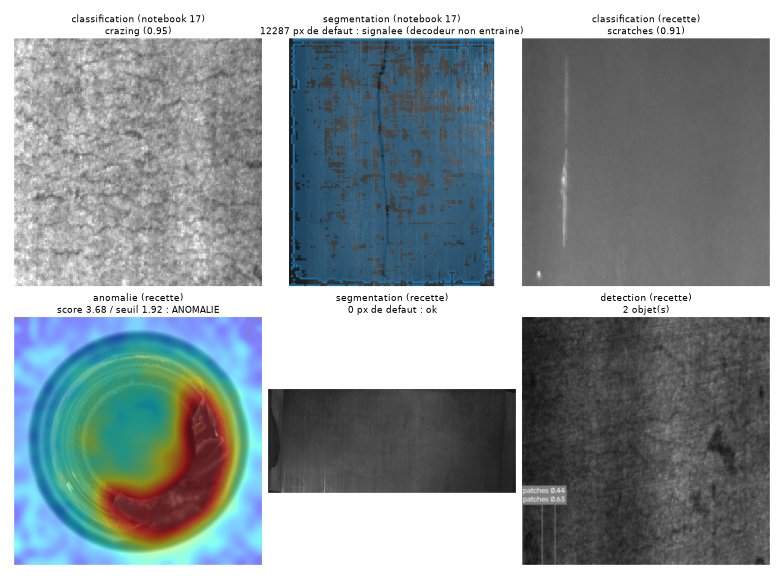

In [5]:
class Predictor:  # predicteur complet : charge le modele une fois, predit autant de fois qu'il faut
    def __init__(self, model_dir: str | Path) -> None:  # charge la carte et le modele ONNX
        self.model_dir = Path(model_dir)  # dossier du modele
        self.card = read_card(self.model_dir)  # sa carte
        onnx_file = self.model_dir / self.card["files"].get("onnx", "model.onnx")  # fichier ONNX donne par la carte (defaut model.onnx)
        # session ONNX Runtime sur CPU : le reseau charge et pret a calculer
        self.session = ort.InferenceSession(str(onnx_file), providers=["CPUExecutionProvider"])
        self.input_name = self.session.get_inputs()[0].name  # nom de l'entree du graphe
        self.output_names = [o.name for o in self.session.get_outputs()]  # noms des sorties, dans l'ordre
        spec = self.card["input"]  # description de l'entree
        self.color = spec.get("read_color") or ("gray" if spec["color"] == "GRAY" else "rgb")  # couleur de lecture du fichier
        self.last_outputs: dict = {}  # sorties brutes de la derniere prediction (utiles pour l'affichage)

    def __call__(self, image: np.ndarray) -> dict:  # predicteur(image) : renvoie la reponse lisible
        tensor, meta = prepare(self.card, image)  # image -> tenseur (1, C, H, W)
        # execute le reseau (None = toutes les sorties) et associe chaque sortie a son nom
        self.last_outputs = dict(zip(self.output_names, self.session.run(None, {self.input_name: tensor})))
        return postprocess(self.card, self.last_outputs, meta)  # sorties -> reponse


predictors = {name: Predictor(model_dir) for name, (model_dir, _) in MODELS.items()}  # un predicteur par modele trouve
panels, titles, timings = [], [], {}  # images, titres et durees a afficher
for name, predictor in predictors.items():  # pour chaque modele
    paths = MODELS[name][1]  # ses images
    image = read_image(paths[0], predictor.color)  # la premiere, lue comme le veut la carte
    start = time.perf_counter()  # chronometre
    for p in paths[:N_GOLDEN]:  # sur les N_GOLDEN premieres images
        predictor(read_image(p, predictor.color))  # chaine complete : lecture + prediction
    timings[name] = 1000 * (time.perf_counter() - start) / min(N_GOLDEN, len(paths))  # duree moyenne par image, en ms
    result = predictor(image)  # reponse pour la premiere image
    task = predictor.card["task"]  # la tache du modele
    if task == "classification":  # classification
        panel, title = image, f"{result['label']} ({result['probability']:.2f})"  # l'image telle quelle ; classe et probabilite
    elif task == "anomaly":  # anomalie
        amap = predictor.last_outputs["anomaly_map"][0, 0]  # carte d'anomalie (1re image, 1er canal)
        # carte de chaleur fondue sur l'image, echelle de 0 a 2 x le seuil pixel (ou le max de la carte si pas de seuil)
        panel = viz.overlay_heatmap(image, amap, vmin=0, vmax=2 * predictor.card["thresholds"].get("pixel", float(amap.max())))
        # titre : score de l'image, seuil, et decision (ANOMALIE si le score depasse le seuil)
        title = f"score {result['score']:.2f} / seuil {result['threshold']:.2f} : {'ANOMALIE' if result['anomaly'] else 'normal'}"
    elif task == "segmentation":  # segmentation
        panel, title = (  # deux valeurs a la fois
            viz.overlay_mask(image, result["mask"]),  # masque colore sur l'image
            f"{result['defect_pixels']} px de defaut : {'signalee' if result['flagged'] else 'ok'}",  # surface et decision
        )
    else:  # detection
        objects = result["objects"]  # les objets trouves
        panel = viz.draw_boxes(  # boites dessinees sur l'image, avec classe et score
            image,  # l'image
            [o["box"] for o in objects],  # les coins de chaque boite
            labels=[o["label"] for o in objects],  # le nom de classe de chaque boite
            scores=[o["score"] for o in objects],  # le score de chaque boite
            min_side=400,  # agrandit d'abord les petites images : texte lisible
        )
        title = f"{result['count']} objet(s)"  # nombre d'objets trouves
    panels.append(panel)  # ajoute l'image a la planche
    if "non entraine" in predictor.card.get("notes", ""):  # modele de demonstration (dit dans les notes de la carte)
        title += " (decodeur non entraine)"  # on le signale dans le titre
    titles.append(f"{name}\n{title}")  # titre complet : nom du modele, retour a la ligne, resultat
viz.grid(panels, titles, ncols=3, size=3.2, max_side=320)  # planche de toutes les predictions, 3 par ligne
display(  # tableau des durees par image
    pd.Series(  # une valeur par modele
        {k: round(v, 1) for k, v in timings.items()},  # duree par modele, arrondie a 0,1 ms
        name="ms par image (lecture + pretraitement + reseau + post-traitement)",  # nom de la colonne
    ).to_frame()  # serie -> tableau d'une colonne
)

## 5. Le service HTTP

Le meme predicteur derriere trois routes : `GET /health` (le service est-il vivant ?),
`GET /card` (quel modele, quelles classes, quels seuils ?) et `POST /predict` (un fichier image
-> une reponse JSON). Le masque de segmentation ne part pas en JSON (trop gros). Le service ne
connait que le dossier exporte : le meme code sert les quatre taches.

En vrai : `uvicorn` sur un port (`python -m vtb.serve --model <dossier> --port 8000`), ou l'image
Docker `docker/Dockerfile.serve` (sans PyTorch). Ici, `TestClient` appelle le service sans reseau.

In [6]:
def decode_image(data: bytes, color: str) -> np.ndarray:  # decode les octets d'un fichier envoye ; renvoie l'image
    flag = (cv2.IMREAD_GRAYSCALE if color == "gray" else cv2.IMREAD_COLOR) | cv2.IMREAD_ANYDEPTH  # gris ou couleur ; garde le 16 bits
    image = cv2.imdecode(np.frombuffer(data, np.uint8), flag)  # octets en memoire -> image
    if image is None:  # octets illisibles (pas une image)
        raise ValueError("fichier image illisible")  # erreur claire, transformee plus loin en reponse 400
    return image if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # gris tel quel ; couleur BGR -> RGB


def create_app(model_dir: str | Path) -> FastAPI:  # cree le service web d'un modele ; renvoie l'application FastAPI
    predictor = Predictor(model_dir)  # charge le modele une seule fois, au demarrage du service
    app = FastAPI(title=f"{predictor.card['task']} - {predictor.card['model_name']}")  # l'application, avec un titre

    @app.get("/health")  # route GET /health : le service est-il vivant ?
    def health() -> dict:  # renvoie l'etat du service
        return {"status": "ok", "task": predictor.card["task"], "model": predictor.card["model_name"]}  # FastAPI le convertit en JSON

    @app.get("/card")  # route GET /card : quel modele, quelles classes, quels seuils ?
    def card() -> dict:  # renvoie la carte du modele
        return predictor.card  # la carte entiere, en JSON

    @app.post("/predict")  # route POST /predict : on envoie un fichier image, on recoit la reponse
    async def predict(file: Annotated[UploadFile, File()]) -> dict:  # async : attend le fichier sans bloquer le service
        try:  # le fichier recu peut ne pas etre une image
            image = decode_image(await file.read(), predictor.color)  # await : attend les octets du fichier, puis decode
        except ValueError as error:  # fichier illisible
            raise HTTPException(status_code=400, detail=str(error)) from error  # reponse 400 = "requete invalide", avec la raison
        start = time.perf_counter()  # chronometre
        result = predictor(image)  # prediction
        result.pop("mask", None)  # retire le masque (trop gros pour du JSON) s'il existe
        return {**result, "filename": file.filename, "ms": round(1000 * (time.perf_counter() - start), 2)}  # + nom et duree (ms)

    return app  # l'application prete a servir


responses = {}  # reponse du service pour chaque modele
for name, (model_dir, paths) in MODELS.items():  # pour chaque modele
    client = TestClient(create_app(model_dir))  # client de test : appelle le service sans reseau
    assert client.get("/health").json()["status"] == "ok"  # verifie que le service repond
    # envoie la premiere image : (nom du fichier, octets, type de contenu)
    reply = client.post("/predict", files={"file": (paths[0].name, paths[0].read_bytes(), "application/octet-stream")})
    responses[name] = reply.json()  # reponse JSON decodee en dict
    bad = client.post("/predict", files={"file": ("vide.png", b"pas une image", "image/png")})  # faux fichier : doit etre refuse
print(json.dumps(responses[next(iter(responses))], indent=1)[:600])  # debut de la reponse du premier modele
print("fichier invalide ->", bad.status_code, bad.json())  # code 400 et message d'erreur

{
 "label": "crazing",
 "probability": 0.9453469996765151,
 "probabilities": {
  "crazing": 0.945347,
  "inclusion": 0.00089,
  "patches": 0.003311,
  "pitted": 0.049768,
  "rolled": 0.000177,
  "scratches": 0.000508
 },
 "filename": "Cr_1.bmp",
 "ms": 20.08
}
fichier invalide -> 400 {'detail': 'fichier image illisible'}


## 6. Fichiers de reference pour le programme C#

Pour chaque modele : quelques images copiees et, pour chacune, ce que Python attend :
- la forme, la SOMME et les premieres valeurs du tenseur d'entree : verifie le pretraitement
  (un ecart ici = une operation mal portee, une interpolation, un arrondi) ;
- la reponse complete : verifie le post-traitement (seuil, NMS, decodage).

Meme format que `tools/make_golden.py`. Cote C# (poste Windows, SDK .NET 8) :

```
cd csharp\VtbInference
dotnet run -c Release -- --model <dossier du modele> --golden <dossier golden>\golden.json
```

Attendu : `entree OK` et `sortie OK` pour chaque image, puis "golden : tout est identique a Python".

In [7]:
def jsonable(value):  # convertit une reponse en types simples, ecrivables en JSON (le masque est retire)
    if isinstance(value, dict):  # dict : convertit chaque valeur
        return {k: jsonable(v) for k, v in value.items() if k != "mask"}  # en sautant la cle "mask" (appel recursif)
    if isinstance(value, list | tuple):  # liste ou tuple
        return [jsonable(v) for v in value]  # convertit chaque element
    if isinstance(value, np.floating | np.integer | np.bool_):  # nombre ou booleen numpy (JSON ne les connait pas)
        return value.item()  # -> nombre ou booleen Python
    return value  # deja un type simple


golden_dirs = {}  # dossier de reference de chaque modele
for name, (model_dir, paths) in MODELS.items():  # pour chaque modele
    predictor = predictors[name]  # son predicteur
    folder = OUT / "golden" / model_dir.name  # dossier de reference du modele
    (folder / "golden").mkdir(parents=True, exist_ok=True)  # sous-dossier des images copiees
    items = []  # une entree par image
    for path in paths[:N_GOLDEN]:  # pour chaque image de reference
        target = folder / "golden" / path.name  # ou la copier
        shutil.copy2(path, target)  # copie (avec la date du fichier)
        image = read_image(target, predictor.color)  # relit la copie, comme le fera le programme C#
        tensor, _ = prepare(predictor.card, image)  # tenseur d'entree attendu (_ : meta inutile ici)
        items.append(  # ajoute ce que Python attend pour cette image
            {  # une entree du fichier golden
                "file": f"golden/{path.name}",  # chemin relatif de l'image
                "tensor_shape": list(tensor.shape),  # forme du tenseur d'entree
                "tensor_sum": float(tensor.astype(np.float64).sum()),  # somme de toutes les valeurs (float64 : precise)
                "tensor_first_values": [round(float(v), 6) for v in tensor.ravel()[:8]],  # les 8 premieres valeurs, 6 decimales
                "result": jsonable(predictor(image)),  # la reponse complete attendue
            }
        )
    payload = {"task": predictor.card["task"], "model_name": predictor.card["model_name"], "images": items}  # contenu du fichier
    (folder / "golden.json").write_text(json.dumps(payload, indent=1), encoding="utf-8")  # ecrit golden.json
    golden_dirs[name] = folder  # retient le dossier
    # affiche la commande a lancer cote C# pour verifier ce modele avec ses fichiers de reference
    print(f"{name:30s} {len(items)} images -> dotnet run -c Release -- --model {model_dir} --golden {folder / 'golden.json'}")

classification (notebook 17)   5 images -> dotnet run -c Release -- --model outputs/notebooks/17_export_onnx/classifier --golden outputs/notebooks/18_prediction_production/golden/classifier/golden.json
segmentation (notebook 17)     5 images -> dotnet run -c Release -- --model outputs/notebooks/17_export_onnx/segmenter --golden outputs/notebooks/18_prediction_production/golden/segmenter/golden.json


classification (recette)       5 images -> dotnet run -c Release -- --model outputs/classification/resnet18_head --golden outputs/notebooks/18_prediction_production/golden/resnet18_head/golden.json


anomalie (recette)             5 images -> dotnet run -c Release -- --model outputs/anomaly/patchcore_lite_bottle --golden outputs/notebooks/18_prediction_production/golden/patchcore_lite_bottle/golden.json
segmentation (recette)         5 images -> dotnet run -c Release -- --model outputs/segmentation/unet_resnet18_tile_cpu --golden outputs/notebooks/18_prediction_production/golden/unet_resnet18_tile_cpu/golden.json


detection (recette)            5 images -> dotnet run -c Release -- --model outputs/detection/quick_yolo --golden outputs/notebooks/18_prediction_production/golden/quick_yolo/golden.json


## 7. Resultats et passage en production

En production, ce code existe deja, teste : `vtb.serve.predictor.OnnxPredictor` (predicteur),
`vtb.serve.app.create_app` (service), `tools/make_golden.py` (fichiers de reference) :

```
python -m vtb.serve --model outputs/notebooks/17_export_onnx/classifier --port 8000
curl -F "file=@piece.png" http://localhost:8000/predict
python tools/make_golden.py --model outputs/notebooks/17_export_onnx/classifier --images data/raw/neu_cls_flat/crazing --n 5
docker build -f docker/Dockerfile.serve -t vtb-serve .
```

Controle : le predicteur ecrit a la main et celui de la toolbox donnent le meme tenseur d'entree
et la meme reponse, image par image, pour chaque modele ; le service de la toolbox repond comme
celui du notebook.

In [8]:
from vtb.serve.app import create_app as vtb_create_app  # service de la toolbox, renomme pour ne pas ecraser le notre
from vtb.serve.predictor import OnnxPredictor  # predicteur de production de la toolbox


def same_result(a: dict, b: dict) -> bool:  # vrai si deux reponses sont identiques (flottants a 1e-6 pres)
    if a.keys() != b.keys():  # pas les memes champs
        return False  # differentes
    for key in a:  # pour chaque champ
        x, y = a[key], b[key]  # les deux valeurs a comparer
        if isinstance(x, np.ndarray):  # tableau numpy (un masque)
            if not np.array_equal(x, y):  # au moins un pixel different
                return False  # differentes
        elif isinstance(x, dict):  # sous-dictionnaire
            if not same_result(x, y):  # comparaison recursive (la fonction s'appelle elle-meme)
                return False  # differentes
        elif isinstance(x, list) and x and isinstance(x[0], dict):  # liste non vide de dicts (les objets detectes)
            if len(x) != len(y) or not all(same_result(u, v) for u, v in zip(x, y)):  # pas le meme nombre, ou un objet different
                return False  # differentes
        elif isinstance(x, float):  # nombre a virgule
            if abs(x - y) > 1e-6:  # ecart au-dela de l'arrondi
                return False  # differentes
        elif x != y:  # autre valeur (texte, entier, liste simple) differente
            return False  # differentes
    return True  # tout est identique


rows = []  # une ligne de resultat par modele
for name, (model_dir, paths) in MODELS.items():  # pour chaque modele
    mine, theirs = predictors[name], OnnxPredictor(model_dir)  # notre predicteur et celui de la toolbox
    tensor_gap, identical = 0.0, True  # plus grand ecart de tenseur ; "reponses identiques" jusqu'ici
    for path in paths[:N_GOLDEN]:  # pour chaque image de reference
        image = read_image(path, mine.color)  # lecture comme le dit la carte
        # plus grand ecart entre les deux tenseurs d'entree, sur toutes les images vues
        tensor_gap = max(tensor_gap, float(np.abs(prepare(mine.card, image)[0] - theirs.prepare(image)[0]).max()))
        identical &= same_result(mine(image), theirs(image))  # &= : reste vrai seulement si toutes les reponses concordent
    reply = TestClient(vtb_create_app(model_dir)).post(  # le service de la toolbox recoit la premiere image
        "/predict",  # la route de prediction
        files={"file": (paths[0].name, paths[0].read_bytes(), "application/octet-stream")},  # le fichier envoye
    )
    same_service = same_result(  # meme reponse que notre service ? (sans la duree "ms", qui varie d'un appel a l'autre)
        {k: v for k, v in reply.json().items() if k != "ms"},  # reponse du service de la toolbox, sans "ms"
        {k: v for k, v in responses[name].items() if k != "ms"},  # reponse de notre service, sans "ms"
    )
    rows.append(  # ajoute la ligne de ce modele
        {  # colonnes du tableau final
            "modele": name,  # nom du modele
            "tache": mine.card["task"],  # sa tache
            "ms / image": round(timings[name], 1),  # duree moyenne par image
            "ecart max du tenseur d'entree": tensor_gap,  # doit valoir 0 : pretraitement identique
            "reponses identiques": identical,  # notre predicteur = celui de la toolbox
            "service identique": same_service,  # notre service = celui de la toolbox
            "golden": str(golden_dirs[name] / "golden.json"),  # fichier de reference ecrit pour le C#
        }
    )
results = pd.DataFrame(rows).set_index("modele")  # tableau, une ligne par modele (indexe par son nom)
display(results)  # affiche le tableau
# arrete le notebook avec une erreur si un controle echoue (reponses, service, tenseur d'entree)
assert results["reponses identiques"].all() and results["service identique"].all() and (results["ecart max du tenseur d'entree"] == 0).all()

,tache,ms / image,ecart max du tenseur d'entree,reponses identiques,service identique,golden
modele,,,,,,
classification (notebook 17),classification,7.7,0.0,True,True,outputs/notebooks/18_prediction_production/gol...
segmentation (notebook 17),segmentation,21.0,0.0,True,True,outputs/notebooks/18_prediction_production/gol...
classification (recette),classification,10.1,0.0,True,True,outputs/notebooks/18_prediction_production/gol...
anomalie (recette),anomaly,48.0,0.0,True,True,outputs/notebooks/18_prediction_production/gol...
segmentation (recette),segmentation,14.4,0.0,True,True,outputs/notebooks/18_prediction_production/gol...
detection (recette),detection,16.1,0.0,True,True,outputs/notebooks/18_prediction_production/gol...


## Pour aller plus loin

- Porter un decodeur de plus (YOLOX, RF-DETR, Faster R-CNN) : le reprendre de
  `src/vtb/serve/predictor.py`, puis refaire la verification de la section 7 sur ses modeles.
- Mesurer la latence de bout en bout sur le poste de production (lecture comprise) : c'est elle
  qui compte pour la cadence de la ligne, pas celle du seul reseau.
- Journaliser chaque prediction (image, version du modele, reponse) : c'est la matiere premiere
  de la surveillance de derive (notebook 05).